In [ ]:
# ╔══════════════════════════════════════════════════════════════╗
# ║  CELLULE 0 : INTERFACE DE SÉLECTION DU DATASET (upload PC)   ║
# ╚══════════════════════════════════════════════════════════════╝
# Remplace l'ancien chargement Hugging Face (load_dataset).
# Un bouton « Choose files » s'affiche : tu sélectionnes ton fichier sur ton PC.
# Formats acceptés : .parquet, .csv, .xlsx / .xls, .pkl

from google.colab import files
import pandas as pd
import io
import os

# Colonnes dont le reste du notebook a besoin (celles de data_jobs)
COLONNES_ATTENDUES = ["job_title", "job_title_short", "company_name",
                      "job_skills", "job_type_skills"]

print("📂 Clique sur « Choose files » et sélectionne ton dataset (ex : data_jobs.csv)...")
fichiers = files.upload()                      # ouvre la fenêtre de sélection de fichier

# On récupère le nom du fichier choisi et son extension
nom = list(fichiers.keys())[0]
extension = os.path.splitext(nom)[1].lower()
contenu = io.BytesIO(fichiers[nom])            # contenu du fichier gardé en mémoire

# Lecture selon le format du fichier
if extension == ".parquet":
    df = pd.read_parquet(contenu)
elif extension == ".csv":
    df = pd.read_csv(contenu)
elif extension in (".xlsx", ".xls"):
    df = pd.read_excel(contenu)
elif extension in (".pkl", ".pickle"):
    df = pd.read_pickle(contenu)
else:
    raise ValueError(f"Format non supporté : {extension} (utilise parquet, csv, xlsx ou pkl)")

# Vérification : toutes les colonnes nécessaires doivent exister
manquantes = [c for c in COLONNES_ATTENDUES if c not in df.columns]
if manquantes:
    raise ValueError(f"Colonnes manquantes dans ton dataset : {manquantes}")

print(f"✅ Fichier chargé : {nom}")
print(df.shape)                                # (nb de lignes, nb de colonnes)

📂 Clique sur « Choose files » et sélectionne ton dataset (ex : data_jobs.csv)...


Saving data_jobs.csv to data_jobs.csv
✅ Fichier chargé : data_jobs.csv
(785741, 17)


In [ ]:
# Affiche les 5 premières lignes pour voir à quoi ressemblent les offres
df.head(5)

,job_title_short,job_title,job_location,job_via,job_schedule_type,job_work_from_home,search_location,job_posted_date,job_no_degree_mention,job_health_insurance,job_country,salary_rate,salary_year_avg,salary_hour_avg,company_name,job_skills,job_type_skills
0,Senior Data Engineer,Senior Clinical Data Engineer / Principal Clin...,"Watertown, CT",via Work Nearby,Full-time,False,"Texas, United States",2023-06-16 13:44:15,False,False,United States,NaN,NaN,NaN,Boehringer Ingelheim,NaN,NaN
1,Data Analyst,Data Analyst,"Guadalajara, Jalisco, Mexico",via BeBee México,Full-time,False,Mexico,2023-01-14 13:18:07,False,False,Mexico,NaN,NaN,NaN,Hewlett Packard Enterprise,"['r', 'python', 'sql', 'nosql', 'power bi', 't...","{'analyst_tools': ['power bi', 'tableau'], 'pr..."
2,Data Engineer,"Data Engineer/Scientist/Analyst, Mid or Senior...","Berlin, Germany",via LinkedIn,Full-time,False,Germany,2023-10-10 13:14:55,False,False,Germany,NaN,NaN,NaN,ALPHA Augmented Services,"['python', 'sql', 'c#', 'azure', 'airflow', 'd...","{'analyst_tools': ['dax'], 'cloud': ['azure'],..."
3,Data Engineer,LEAD ENGINEER - PRINCIPAL ANALYST - PRINCIPAL ...,"San Antonio, TX",via Diversity.com,Full-time,False,"Texas, United States",2023-07-04 13:01:41,True,False,United States,NaN,NaN,NaN,Southwest Research Institute,"['python', 'c++', 'java', 'matlab', 'aws', 'te...","{'cloud': ['aws'], 'libraries': ['tensorflow',..."
4,Data Engineer,Data Engineer- Sr Jobs,"Washington, DC",via Clearance Jobs,Full-time,False,Sudan,2023-08-07 14:29:36,False,False,Sudan,NaN,NaN,NaN,Kristina Daniel,"['bash', 'python', 'oracle', 'aws', 'ansible',...","{'cloud': ['oracle', 'aws'], 'other': ['ansibl..."


In [ ]:
# Types de colonnes et valeurs manquantes (on repère ici que job_skills a des NaN)
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 785741 entries, 0 to 785740
Data columns (total 17 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   job_title_short        785741 non-null  object 
 1   job_title              785740 non-null  object 
 2   job_location           784696 non-null  object 
 3   job_via                785733 non-null  object 
 4   job_schedule_type      773074 non-null  object 
 5   job_work_from_home     785741 non-null  bool   
 6   search_location        785741 non-null  object 
 7   job_posted_date        785741 non-null  object 
 8   job_no_degree_mention  785741 non-null  bool   
 9   job_health_insurance   785741 non-null  bool   
 10  job_country            785692 non-null  object 
 11  salary_rate            33067 non-null   object 
 12  salary_year_avg        22003 non-null   float64
 13  salary_hour_avg        10662 non-null   float64
 14  company_name           785723 non-nu

In [ ]:
# Nombre d'offres par type de poste (Data Analyst, Data Engineer...) : montre le déséquilibre
df["job_title_short"].value_counts()

,count
job_title_short,
Data Analyst,196075
Data Engineer,186241
Data Scientist,172286
Business Analyst,49063
Software Engineer,44929
Senior Data Engineer,44563
Senior Data Scientist,36957
Senior Data Analyst,29216
Machine Learning Engineer,14080


In [ ]:
# On regarde UNE ligne pour comprendre le format de job_skills
exemple = df["job_skills"].iloc[1]
print(exemple)
print(type(exemple))   # c'est un TEXTE (str), pas une liste : il faudra le convertir

['r', 'python', 'sql', 'nosql', 'power bi', 'tableau']
<class 'str'>


In [ ]:
import ast

# 1) Garder seulement les offres qui ont des compétences
df_clean = df.dropna(subset=["job_skills"]).copy()

# 2) Convertir le texte en vraie liste
#    "['python', 'sql']" (str)  ->  ['python', 'sql'] (list)
df_clean["job_skills"] = df_clean["job_skills"].apply(ast.literal_eval)
df_clean["job_type_skills"] = df_clean["job_type_skills"].apply(ast.literal_eval)

# Vérification
print(df_clean.shape)
exemple = df_clean["job_skills"].iloc[0]
print(exemple)
print(type(exemple))   # doit afficher <class 'list'>

(668704, 17)
['r', 'python', 'sql', 'nosql', 'power bi', 'tableau']
<class 'list'>


In [ ]:
# On prend 2000 offres PAR type de poste, pour que chaque poste pèse pareil
# (random_state=42 : le tirage est reproductible)
df_sample = (
    df_clean
    .groupby("job_title_short")
    .sample(n=2000, random_state=42)
    .reset_index(drop=True)
)

print(df_sample.shape)
print(df_sample["job_title_short"].value_counts())   # doit afficher 2000 partout

(20000, 17)
job_title_short
Business Analyst             2000
Cloud Engineer               2000
Data Analyst                 2000
Data Engineer                2000
Data Scientist               2000
Machine Learning Engineer    2000
Senior Data Analyst          2000
Senior Data Engineer         2000
Senior Data Scientist        2000
Software Engineer            2000
Name: count, dtype: int64


In [ ]:
# Contrôle visuel du tableau nettoyé (avant échantillonnage)
df_clean.head(5)

,job_title_short,job_title,job_location,job_via,job_schedule_type,job_work_from_home,search_location,job_posted_date,job_no_degree_mention,job_health_insurance,job_country,salary_rate,salary_year_avg,salary_hour_avg,company_name,job_skills,job_type_skills
1,Data Analyst,Data Analyst,"Guadalajara, Jalisco, Mexico",via BeBee México,Full-time,False,Mexico,2023-01-14 13:18:07,False,False,Mexico,NaN,NaN,NaN,Hewlett Packard Enterprise,"[r, python, sql, nosql, power bi, tableau]","{'analyst_tools': ['power bi', 'tableau'], 'pr..."
2,Data Engineer,"Data Engineer/Scientist/Analyst, Mid or Senior...","Berlin, Germany",via LinkedIn,Full-time,False,Germany,2023-10-10 13:14:55,False,False,Germany,NaN,NaN,NaN,ALPHA Augmented Services,"[python, sql, c#, azure, airflow, dax, docker,...","{'analyst_tools': ['dax'], 'cloud': ['azure'],..."
3,Data Engineer,LEAD ENGINEER - PRINCIPAL ANALYST - PRINCIPAL ...,"San Antonio, TX",via Diversity.com,Full-time,False,"Texas, United States",2023-07-04 13:01:41,True,False,United States,NaN,NaN,NaN,Southwest Research Institute,"[python, c++, java, matlab, aws, tensorflow, k...","{'cloud': ['aws'], 'libraries': ['tensorflow',..."
4,Data Engineer,Data Engineer- Sr Jobs,"Washington, DC",via Clearance Jobs,Full-time,False,Sudan,2023-08-07 14:29:36,False,False,Sudan,NaN,NaN,NaN,Kristina Daniel,"[bash, python, oracle, aws, ansible, puppet, j...","{'cloud': ['oracle', 'aws'], 'other': ['ansibl..."
5,Data Engineer,GCP Data Engineer,Anywhere,via ZipRecruiter,Contractor and Temp work,True,Georgia,2023-11-07 14:01:59,False,False,United States,NaN,NaN,NaN,smart folks inc,"[python, sql, gcp]","{'cloud': ['gcp'], 'programming': ['python', '..."


In [ ]:
# On ne garde à l'affichage que les 5 colonnes utiles au projet
colonnes = ["job_title", "job_title_short", "company_name", "job_skills", "job_type_skills"]
df_sample[colonnes].head(10)

,job_title,job_title_short,company_name,job_skills,job_type_skills
0,Operations Analyst,Business Analyst,AstraZeneca,"[power bi, jira]","{'analyst_tools': ['power bi'], 'async': ['jir..."
1,Analyst,Business Analyst,Kelly Services,"[excel, outlook, word]","{'analyst_tools': ['excel', 'outlook', 'word']}"
2,Delivery Engineer Jr,Business Analyst,Softline International,"[windows, sharepoint]","{'analyst_tools': ['sharepoint'], 'os': ['wind..."
3,QA Engineer,Business Analyst,jameda GmbH,"[go, javascript, typescript, flow, git]","{'other': ['flow', 'git'], 'programming': ['go..."
4,Business Analyst,Business Analyst,Hays,"[python, dax]","{'analyst_tools': ['dax'], 'programming': ['py..."
5,Data Engineer and Business Analyst,Business Analyst,NTT DATA,"[sql, nosql, java, python, c#, golang, hadoop,...","{'analyst_tools': ['sap'], 'libraries': ['hado..."
6,Hiring for Business Analyst,Business Analyst,3i Infotech Limited,"[sas, sas, spss]","{'analyst_tools': ['sas', 'spss'], 'programmin..."
7,Sr Growth Business Intelligence Analyst,Business Analyst,Paychex,"[python, sql, r, ssis]","{'analyst_tools': ['ssis'], 'programming': ['p..."
8,Desarrollador Bi,Business Analyst,Dicsys,"[python, oracle, power bi]","{'analyst_tools': ['power bi'], 'cloud': ['ora..."
9,Business Analyst - Healthcare,Business Analyst,HIRD LLC,"[sql, flow]","{'other': ['flow'], 'programming': ['sql']}"


In [ ]:
# CELLULE DÉSACTIVÉE : on n'utilise plus Google Drive.
# (Avant, cette cellule montait ton Drive avec drive.mount.)
# Les sauvegardes se font maintenant dans le dossier local de Colab : /content/SkillGraph
# Attention : ce dossier est supprimé quand la session Colab se ferme.
print("Google Drive non utilisé : sauvegardes dans /content/SkillGraph")

Google Drive non utilisé : sauvegardes dans /content/SkillGraph


In [ ]:
import os

# Dossier du projet, local à Colab (créé s'il n'existe pas)
dossier = "/content/SkillGraph"
os.makedirs(dossier, exist_ok=True)

# Sauvegarde en pickle : on pourra recharger l'échantillon pendant cette session
df_sample.to_pickle(f"{dossier}/df_sample.pkl")
print("Sauvegardé ✅")

Sauvegardé ✅


In [ ]:
import re

def pretraiter(titre):
    titre = titre.lower()                          # minuscules
    titre = re.sub(r"[^a-z0-9+#\s]", " ", titre)   # enlever la ponctuation (en gardant + et # pour c++ / c#)
    titre = re.sub(r"\s+", " ", titre).strip()     # enlever les espaces en trop
    return titre

# Nouvelle colonne avec le titre nettoyé (fillna : évite une erreur sur les titres vides)
df_sample["titre_clean"] = df_sample["job_title"].fillna("").apply(pretraiter)

df_sample[["job_title", "titre_clean"]].head(10)   # avant / après

,job_title,titre_clean
0,Operations Analyst,operations analyst
1,Analyst,analyst
2,Delivery Engineer Jr,delivery engineer jr
3,QA Engineer,qa engineer
4,Business Analyst,business analyst
5,Data Engineer and Business Analyst,data engineer and business analyst
6,Hiring for Business Analyst,hiring for business analyst
7,Sr Growth Business Intelligence Analyst,sr growth business intelligence analyst
8,Desarrollador Bi,desarrollador bi
9,Business Analyst - Healthcare,business analyst healthcare


In [ ]:
from sklearn.model_selection import train_test_split

X = df_sample["titre_clean"]        # ce qu'on donne au modèle : le titre
y = df_sample["job_title_short"]    # ce qu'il doit deviner : la catégorie du poste

# 80 % pour apprendre, 20 % pour tester
# stratify=y : chaque catégorie est représentée pareil dans train et test
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Train :", len(X_train))
print("Test  :", len(X_test))

Train : 16000
Test  : 4000


In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

vectoriseur = TfidfVectorizer(
    stop_words="english",           # enlever and, for, the...
    token_pattern=r"[a-z0-9+#]+"    # découper en mots, en gardant c++ et c#
)

X_train_vec = vectoriseur.fit_transform(X_train)   # apprend le vocabulaire + IDF sur le TRAIN
X_test_vec  = vectoriseur.transform(X_test)        # applique au TEST, sans rien apprendre (évite la fuite de données)

print("Taille du vocabulaire :", len(vectoriseur.vocabulary_))
print("Train vectorisé :", X_train_vec.shape)
print("Test vectorisé  :", X_test_vec.shape)

Taille du vocabulaire : 3775
Train vectorisé : (16000, 3775)
Test vectorisé  : (4000, 3775)


In [ ]:
from sklearn.linear_model import LogisticRegression

# Modèle simple : titre (vecteur TF-IDF) -> catégorie du poste
modele = LogisticRegression(max_iter=1000)

modele.fit(X_train_vec, y_train)   # apprentissage sur le train

print("Modèle entraîné ✅")

Modèle entraîné ✅


In [ ]:
from sklearn.metrics import accuracy_score, f1_score, classification_report

y_pred = modele.predict(X_test_vec)   # prédictions sur des titres jamais vus

# Accuracy : % de bonnes réponses / F1 macro : moyenne des F1 par classe (équitable entre postes)
print("Accuracy :", round(accuracy_score(y_test, y_pred), 3))
print("F1 macro :", round(f1_score(y_test, y_pred, average="macro"), 3))
print()
print(classification_report(y_test, y_pred))   # détail précision / rappel par poste

Accuracy : 0.87
F1 macro : 0.871

                           precision    recall  f1-score   support

         Business Analyst       0.81      0.86      0.83       400
           Cloud Engineer       0.77      0.82      0.80       400
             Data Analyst       0.90      0.86      0.88       400
            Data Engineer       0.91      0.89      0.90       400
           Data Scientist       0.88      0.88      0.88       400
Machine Learning Engineer       0.94      0.90      0.92       400
      Senior Data Analyst       0.88      0.89      0.88       400
     Senior Data Engineer       0.92      0.92      0.92       400
    Senior Data Scientist       0.89      0.87      0.88       400
        Software Engineer       0.82      0.82      0.82       400

                 accuracy                           0.87      4000
                macro avg       0.87      0.87      0.87      4000
             weighted avg       0.87      0.87      0.87      4000



In [ ]:
from collections import Counter

# Compte combien de fois chaque compétence apparaît dans toutes les offres
compteur = Counter(
    competence
    for liste in df_sample["job_skills"]
    for competence in liste
)

print("Nombre de compétences différentes :", len(compteur))
compteur.most_common(20)   # les 20 plus demandées

Nombre de compétences différentes : 235


[('python', 10976),
 ('sql', 10117),
 ('aws', 4797),
 ('azure', 4147),
 ('tableau', 3406),
 ('excel', 3379),
 ('r', 3379),
 ('spark', 3110),
 ('java', 2733),
 ('power bi', 2498),
 ('sas', 2174),
 ('hadoop', 1698),
 ('kubernetes', 1667),
 ('docker', 1659),
 ('gcp', 1626),
 ('git', 1593),
 ('scala', 1540),
 ('snowflake', 1508),
 ('databricks', 1451),
 ('kafka', 1377)]

In [ ]:
!pip install -q sentence-transformers

from sentence_transformers import SentenceTransformer

competences = list(compteur.keys())   # liste des compétences uniques

# Modèle BERT léger : transforme un texte en vecteur de 384 nombres
modele_bert = SentenceTransformer("all-MiniLM-L6-v2")

# On ajoute "technical skill:" pour donner du contexte à chaque mot
phrases = [f"technical skill: {c}" for c in competences]
embeddings = modele_bert.encode(phrases, show_progress_bar=True)

print("Nombre de compétences :", len(competences))
print("Taille des embeddings :", embeddings.shape)   # (nb compétences, 384)

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (5 outputs left out)

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/8 [00:00<?, ?it/s]

Nombre de compétences : 235
Taille des embeddings : (235, 384)


In [ ]:
from sklearn.cluster import KMeans
import pandas as pd

# On regroupe les compétences proches en 12 groupes (non supervisé)
k = 12
kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
groupes = kmeans.fit_predict(embeddings)

# Tableau : compétence, groupe, fréquence
df_comp = pd.DataFrame({
    "competence": competences,
    "groupe": groupes,
    "frequence": [compteur[c] for c in competences]
})

# Affiche les 10 compétences les plus fréquentes de chaque groupe
for g in range(k):
    membres = df_comp[df_comp["groupe"] == g].sort_values("frequence", ascending=False)
    print(f"Groupe {g} ({len(membres)} compétences) : {membres['competence'].head(10).tolist()}")

Groupe 0 (12 compétences) : ['excel', 'vba', 'matlab', 'sheets', 'opencv', 'spreadsheet', 'ms access', 'visual basic', 'microsoft teams', 'smartsheet']
Groupe 1 (1 compétences) : ['colocation']
Groupe 2 (56 compétences) : ['tableau', 'r', 'java', 'sas', 'gcp', 'go', 'flow', 'word', 'sap', 'c++']
Groupe 3 (62 compétences) : ['python', 'spark', 'scala', 'snowflake', 'kafka', 'tensorflow', 'pytorch', 'airflow', 'pandas', 'scikit-learn']
Groupe 4 (6 compétences) : ['nosql', 'mongodb', 'dynamodb', 'mongo', 'couchbase', 'couchdb']
Groupe 5 (23 compétences) : ['git', 'linux', 'github', 'shell', 'bash', 'unix', 'powershell', 'vmware', 'perl', 'bitbucket']
Groupe 6 (12 compétences) : ['sql', 'oracle', 'sql server', 'mysql', 'bigquery', 'postgresql', 't-sql', 'db2', 'graphql', 'no-sql']
Groupe 7 (3 compétences) : ['docker', 'flutter', 'dart']
Groupe 8 (11 compétences) : ['javascript', 'react', 'typescript', 'angular', 'node.js', 'jquery', 'vue.js', 'react.js', 'next.js', 'angular.js']
Groupe 9 (

In [ ]:
from sklearn.metrics.pairwise import cosine_similarity

# 1) Similarité cosinus entre toutes les compétences (matrice carrée)
sim = cosine_similarity(embeddings)
index = {c: i for i, c in enumerate(competences)}   # compétence -> position dans la matrice

def similaires(competence, n=5):
    i = index[competence]
    ordre = sim[i].argsort()[::-1]          # du plus proche au plus loin
    return [(competences[j], round(float(sim[i, j]), 2)) for j in ordre if j != i][:n]

# 2) Quelques exemples pour vérifier que les résultats ont du sens
for c in ["python", "aws", "git", "tableau", "mongodb"]:
    print(c, "→", similaires(c))

# 3) Le tableau final de l'enrichissement + sauvegarde
df_comp["similaires"] = [[s for s, _ in similaires(c)] for c in df_comp["competence"]]

dossier = "/content/SkillGraph"   # dossier local de Colab (plus de Drive)
df_comp.to_pickle(f"{dossier}/competences_enrichies.pkl")
print("\nSauvegardé ✅")

df_comp.sort_values("frequence", ascending=False).head(10)

python → [('jupyter', 0.76), ('numpy', 0.75), ('rshiny', 0.75), ('scikit-learn', 0.74), ('django', 0.74)]
aws → [('ibm cloud', 0.68), ('aurora', 0.66), ('sharepoint', 0.65), ('terraform', 0.64), ('ovh', 0.64)]
git → [('github', 0.85), ('gitlab', 0.79), ('sharepoint', 0.66), ('node', 0.65), ('bitbucket', 0.65)]
tableau → [('ovh', 0.74), ('solidity', 0.73), ('word', 0.72), ('r', 0.71), ('c', 0.71)]
mongodb → [('mongo', 0.86), ('nosql', 0.72), ('dynamodb', 0.65), ('couchdb', 0.58), ('mariadb', 0.58)]

Sauvegardé ✅


,competence,groupe,frequence,similaires
12,python,3,10976,"[jupyter, numpy, rshiny, scikit-learn, django]"
14,sql,6,10117,"[no-sql, t-sql, sql server, mysql, oracle]"
36,aws,9,4797,"[ibm cloud, aurora, sharepoint, terraform, ovh]"
60,azure,9,4147,"[sharepoint, phoenix, node, ibm cloud, word]"
32,tableau,2,3406,"[ovh, solidity, word, r, c]"
25,r,2,3379,"[c, rshiny, ovh, word, notion]"
2,excel,0,3379,"[spreadsheet, vba, sheets, smartsheet, matlab]"
21,spark,3,3110,"[ovh, notion, word, r, mattermost]"
16,java,2,2733,"[c#, sharepoint, r, word, notion]"
0,power bi,11,2498,"[powerbi, ovh, r, mattermost, unity]"


In [ ]:
import networkx as nx
from collections import Counter

# 1) Compter les liens dans les offres
liens_ep = Counter()   # (entreprise, poste)
liens_pc = Counter()   # (poste, compétence)

for _, ligne in df_sample.iterrows():
    poste = ligne["job_title_short"]
    liens_ep[(ligne["company_name"], poste)] += 1
    for c in ligne["job_skills"]:
        liens_pc[(poste, c)] += 1

# 2) Garder les entreprises avec au moins 5 offres (sinon le graphe est trop bruité)
freq_ent = df_sample["company_name"].value_counts()
top_entreprises = set(freq_ent[freq_ent >= 5].index)

# 3) Créer le graphe (préfixes P: / C: / E: pour éviter les collisions de noms)
G = nx.Graph()

for p in df_sample["job_title_short"].unique():
    G.add_node("P:" + p, type="poste", label=p)

for _, ligne in df_comp.iterrows():
    G.add_node("C:" + ligne["competence"], type="competence",
               label=ligne["competence"], groupe=int(ligne["groupe"]))

for e in top_entreprises:
    G.add_node("E:" + e, type="entreprise", label=e)

# Arêtes pondérées : weight = nombre d'offres qui relient les deux nœuds
for (e, p), n in liens_ep.items():
    if e in top_entreprises:
        G.add_edge("E:" + e, "P:" + p, weight=n, relation="propose")

for (p, c), n in liens_pc.items():
    G.add_edge("P:" + p, "C:" + c, weight=n, relation="requiert")

# 4) Résumé
types = Counter(nx.get_node_attributes(G, "type").values())
print("Nœuds :", dict(types), "→ total", G.number_of_nodes())
print("Liens :", G.number_of_edges())

# 5) Un exemple : les 5 compétences les plus demandées pour Data Engineer
voisins = [(v, G["P:Data Engineer"][v]["weight"]) for v in G["P:Data Engineer"]
           if G.nodes[v]["type"] == "competence"]
print("\nData Engineer requiert surtout :",
      sorted(voisins, key=lambda x: x[1], reverse=True)[:5])

Nœuds : {'poste': 10, 'competence': 235, 'entreprise': 492} → total 737
Liens : 4191

Data Engineer requiert surtout : [('C:sql', 1333), ('C:python', 1265), ('C:aws', 738), ('C:azure', 709), ('C:spark', 606)]


In [ ]:
from networkx.algorithms.community import louvain_communities

# Louvain regroupe les nœuds très connectés entre eux (en tenant compte des poids)
communautes = louvain_communities(G, weight="weight", seed=42)
print("Nombre de communautés :", len(communautes))

for i, com in enumerate(communautes):
    for n in com:
        G.nodes[n]["communaute"] = i      # on garde la communauté dans le graphe

    # Résumé de chaque communauté : postes, top compétences, nombre d'entreprises
    postes = [G.nodes[n]["label"] for n in com if G.nodes[n]["type"] == "poste"]
    comps = sorted([n for n in com if G.nodes[n]["type"] == "competence"],
                   key=lambda n: G.degree(n, weight="weight"), reverse=True)
    nb_ent = sum(1 for n in com if G.nodes[n]["type"] == "entreprise")

    print(f"\nCommunauté {i}")
    print("  Postes      :", postes)
    print("  Compétences :", [G.nodes[n]["label"] for n in comps[:10]])
    print("  Entreprises :", nb_ent)

Nombre de communautés : 4

Communauté 0
  Postes      : ['Data Analyst', 'Business Analyst', 'Senior Data Analyst']
  Compétences : ['sql', 'tableau', 'excel', 'power bi', 'sas', 'oracle', 'flow', 'word', 'powerpoint', 'sap']
  Entreprises : 160

Communauté 1
  Postes      : ['Senior Data Engineer', 'Data Engineer']
  Compétences : ['aws', 'azure', 'spark', 'hadoop', 'gcp', 'scala', 'snowflake', 'databricks', 'kafka', 'airflow']
  Entreprises : 69

Communauté 2
  Postes      : ['Senior Data Scientist', 'Data Scientist', 'Machine Learning Engineer']
  Compétences : ['python', 'r', 'docker', 'git', 'tensorflow', 'pytorch', 'pandas', 'scikit-learn', 'c++', 'numpy']
  Entreprises : 142

Communauté 3
  Postes      : ['Software Engineer', 'Cloud Engineer']
  Compétences : ['java', 'kubernetes', 'go', 'linux', 'terraform', 'javascript', 'jira', 'jenkins', 'github', 'windows']
  Entreprises : 121


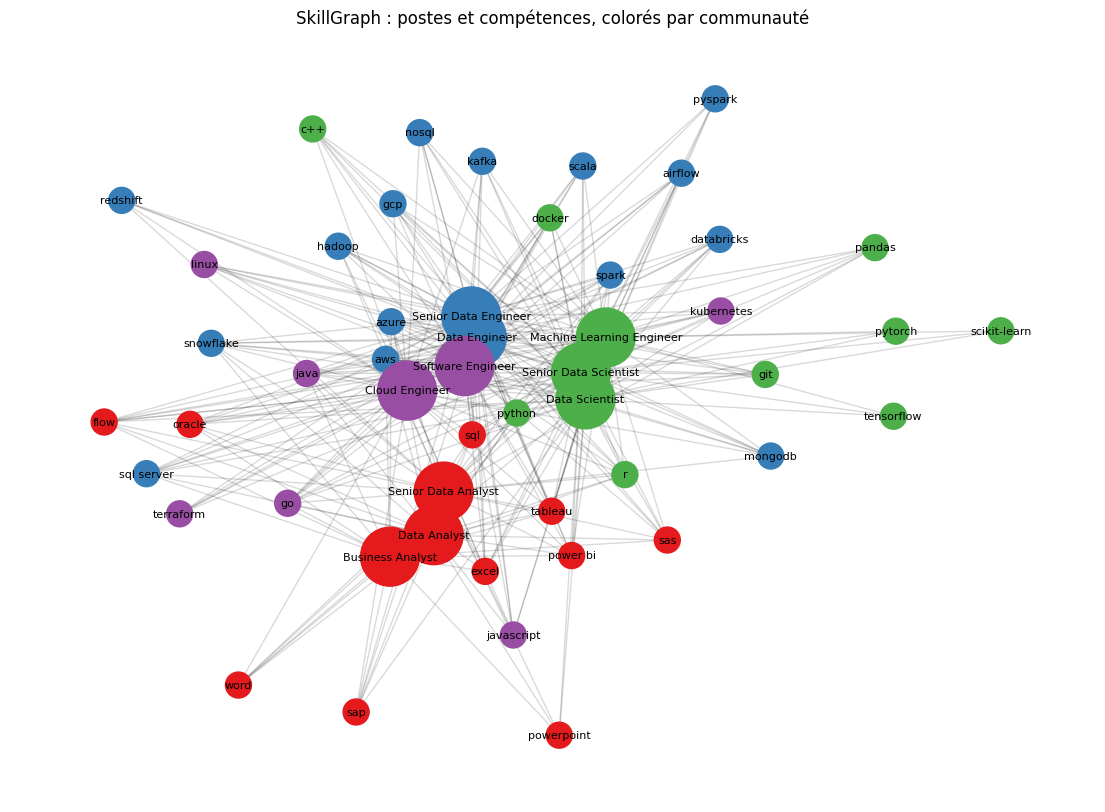

Graphe et image sauvegardés ✅


In [ ]:
import matplotlib.pyplot as plt
import pickle

# On ne dessine que les postes + les 40 compétences les plus connectées (sinon illisible)
postes = [n for n in G if G.nodes[n]["type"] == "poste"]
top_comp = sorted([n for n in G if G.nodes[n]["type"] == "competence"],
                  key=lambda n: G.degree(n, weight="weight"), reverse=True)[:40]
H = G.subgraph(postes + top_comp)

# On garde seulement les liens forts (au moins 50 offres) pour un dessin propre
liens_forts = [(u, v) for u, v, d in H.edges(data=True) if d["weight"] >= 50]
pos = nx.spring_layout(H.edge_subgraph(liens_forts), seed=42, k=0.5)

couleurs = ["#e41a1c", "#377eb8", "#4daf4a", "#984ea3"]   # une couleur par communauté
noeuds = list(pos.keys())

plt.figure(figsize=(14, 10))
nx.draw_networkx_edges(H, pos, edgelist=liens_forts, alpha=0.15)
nx.draw_networkx_nodes(H, pos, nodelist=noeuds,
    node_color=[couleurs[H.nodes[n]["communaute"] % 4] for n in noeuds],
    node_size=[1800 if H.nodes[n]["type"] == "poste" else 350 for n in noeuds])   # postes = gros nœuds
nx.draw_networkx_labels(H, pos, labels={n: H.nodes[n]["label"] for n in noeuds}, font_size=8)
plt.title("SkillGraph : postes et compétences, colorés par communauté")
plt.axis("off")
plt.savefig(f"{dossier}/graphe_communautes.png", dpi=150, bbox_inches="tight")
plt.show()

# Sauvegarde du graphe complet pour le recharger plus tard
with open(f"{dossier}/graphe_G.pkl", "wb") as f:
    pickle.dump(G, f)
print("Graphe et image sauvegardés ✅")

In [ ]:
!pip install -q torch_geometric

import torch
import numpy as np

# 1) Features des nœuds : embeddings BERT
titres = df_sample["titre_clean"].tolist()
x_offres = modele_bert.encode(titres, batch_size=128, show_progress_bar=True)   # (20000, 384)
x_comp = embeddings                                                              # (235, 384)

nb_offres = len(x_offres)
x = torch.tensor(np.vstack([x_offres, x_comp]), dtype=torch.float)
print("Features :", x.shape)    # offres d'abord, puis compétences

# 2) Les liens offre — compétence (chaque lien = couple d'indices de nœuds)
idx_comp = {c: nb_offres + i for i, c in enumerate(competences)}
liens = [(o, idx_comp[c])
         for o, liste in enumerate(df_sample["job_skills"])
         for c in liste]
liens = torch.tensor(liens, dtype=torch.long)
print("Nombre de liens :", len(liens))

# 3) Séparer les liens : 85 % train / 15 % test
torch.manual_seed(42)
perm = torch.randperm(len(liens))
n_test = int(0.15 * len(liens))
liens_test = liens[perm[:n_test]]
liens_train = liens[perm[n_test:]]

# Le GNN fait passer les messages seulement par les liens du train (dans les 2 sens)
edge_index = torch.cat([liens_train.t(), liens_train.t().flip(0)], dim=1)
print("Liens train :", len(liens_train), "| Liens test :", len(liens_test))

Batches:   0%|          | 0/157 [00:00<?, ?it/s]

Features : torch.Size([20235, 384])
Nombre de liens : 110341
Liens train : 93790 | Liens test : 16551


In [ ]:
import torch.nn.functional as F
from torch_geometric.nn import SAGEConv
from sklearn.metrics import roc_auc_score

# Réseau GraphSAGE à 2 couches : 384 -> 128 -> 64 dimensions
class GNN(torch.nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = SAGEConv(384, 128)
        self.conv2 = SAGEConv(128, 64)
    def forward(self, x, edge_index):
        h = self.conv1(x, edge_index).relu()
        return self.conv2(h, edge_index)

# Score d'un lien = produit scalaire des deux vecteurs (plus il est grand, plus le lien est probable)
def score(z, paires):
    return (z[paires[:, 0]] * z[paires[:, 1]]).sum(-1)

# Faux liens (offre, compétence) tirés au hasard : exemples négatifs
def negatifs(n):
    return torch.stack([torch.randint(0, nb_offres, (n,)),
                        torch.randint(nb_offres, nb_offres + len(competences), (n,))], dim=1)

torch.manual_seed(42)
gnn = GNN()
opt = torch.optim.Adam(gnn.parameters(), lr=0.01)

for epoch in range(1, 151):
    gnn.train()
    opt.zero_grad()

    # 1) Séparer : 70 % chemins pour les messages / 30 % liens cachés à deviner
    perm = torch.randperm(len(liens_train))
    n_sup = int(0.3 * len(liens_train))
    a_deviner = liens_train[perm[:n_sup]]
    chemins = liens_train[perm[n_sup:]]

    # 2) 20 % des offres perdent tous leurs chemins (comme un nouveau titre)
    froides = torch.rand(nb_offres) < 0.2
    chemins = chemins[~froides[chemins[:, 0]]]
    ei = torch.cat([chemins.t(), chemins.t().flip(0)], dim=1)

    # 3) Perte : vrais liens -> 1, faux liens -> 0
    z = gnn(x, ei)
    pos = score(z, a_deviner)
    neg = score(z, negatifs(len(a_deviner)))
    loss = F.binary_cross_entropy_with_logits(
        torch.cat([pos, neg]), torch.cat([torch.ones_like(pos), torch.zeros_like(neg)]))
    loss.backward()
    opt.step()

    # 4) Toutes les 10 époques : AUC sur les liens de test jamais vus
    if epoch % 10 == 0:
        gnn.eval()
        with torch.no_grad():
            z = gnn(x, edge_index)
            p = score(z, liens_test)
            n = score(z, negatifs(len(liens_test)))
            auc = roc_auc_score(np.r_[np.ones(len(p)), np.zeros(len(n))], torch.cat([p, n]).numpy())
        print(f"Époque {epoch:3d} | perte {loss.item():.3f} | AUC test {auc:.3f}")

torch.save(gnn.state_dict(), f"{dossier}/gnn.pt")
print("GNN sauvegardé ✅")

/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


Époque  10 | perte 0.700 | AUC test 0.683
Époque  20 | perte 0.697 | AUC test 0.304
Époque  30 | perte 0.693 | AUC test 0.510
Époque  40 | perte 0.631 | AUC test 0.729
Époque  50 | perte 0.571 | AUC test 0.796
Époque  60 | perte 0.506 | AUC test 0.846
Époque  70 | perte 0.469 | AUC test 0.868
Époque  80 | perte 0.442 | AUC test 0.883
Époque  90 | perte 0.415 | AUC test 0.900
Époque 100 | perte 0.397 | AUC test 0.907
Époque 110 | perte 0.391 | AUC test 0.908
Époque 120 | perte 0.381 | AUC test 0.912
Époque 130 | perte 0.389 | AUC test 0.914
Époque 140 | perte 0.375 | AUC test 0.916
Époque 150 | perte 0.370 | AUC test 0.915
GNN sauvegardé ✅


In [ ]:
def recommander(titre, n=8, connues=()):
    # 1) Vectoriser le nouveau titre et l'ajouter comme nouveau nœud du graphe
    emb = modele_bert.encode([pretraiter(titre)])
    x2 = torch.cat([x, torch.tensor(emb, dtype=torch.float)])
    nouveau = x2.shape[0] - 1
    e = edge_index
    if connues:   # si on connaît déjà quelques compétences de l'offre, on les relie
        ids = torch.tensor([idx_comp[c] for c in connues])
        nouv = torch.stack([torch.full_like(ids, nouveau), ids])
        e = torch.cat([edge_index, nouv, nouv.flip(0)], dim=1)
    # 2) Passer dans le GNN
    gnn.eval()
    with torch.no_grad():
        z = gnn(x2, e)
    # 3) Scorer toutes les compétences et garder les meilleures (hors celles déjà connues)
    ids_comp = torch.arange(nb_offres, nb_offres + len(competences))
    scores = (z[nouveau] * z[ids_comp]).sum(-1)
    ordre = scores.argsort(descending=True).tolist()
    return [competences[i] for i in ordre if competences[i] not in connues][:n]

for titre in ["Junior Data Engineer", "Marketing Data Analyst",
              "Deep Learning Researcher", "DevOps Cloud Engineer"]:
    print(f"{titre:28s} → {recommander(titre)}")

print("\nData Engineer qui connaît déjà python →",
      recommander("Data Engineer", connues=("python",)))

Junior Data Engineer         → ['sql', 'python', 'aws', 'java', 'azure', 'spark', 'r', 'tableau']
Marketing Data Analyst       → ['sql', 'excel', 'tableau', 'power bi', 'python', 'sas', 'r', 'powerpoint']
Deep Learning Researcher     → ['python', 'aws', 'tensorflow', 'java', 'azure', 'sql', 'pytorch', 'docker']
DevOps Cloud Engineer        → ['python', 'aws', 'java', 'tensorflow', 'azure', 'docker', 'kubernetes', 'sql']

Data Engineer qui connaît déjà python → ['sql', 'aws', 'java', 'azure', 'spark', 'r', 'tensorflow', 'tableau']


In [ ]:
# Ajouter au graphe la relation directe Entreprise — cherche → Compétence
liens_ec = Counter()
for _, l in df_sample.iterrows():
    if l["company_name"] in top_entreprises:
        for c in l["job_skills"]:
            liens_ec[(l["company_name"], c)] += 1
for (e, c), n in liens_ec.items():
    G.add_edge("E:" + e, "C:" + c, weight=n, relation="cherche")

noms_postes = list(df_sample["job_title_short"].unique())
sim_comp = df_comp.set_index("competence")["similaires"]

# Repère les compétences et les postes cités dans la question (recherche de mots exacts)
def trouver_entites(question):
    q = " " + pretraiter(question) + " "
    comps = [c for c in competences if f" {c} " in q]
    postes = [p for p in noms_postes if f" {p.lower()} " in q]
    # évite les doublons du type "Data Engineer" + "Senior Data Engineer"
    postes = [p for p in postes if not any(p != p2 and p.lower() in p2.lower() for p2 in postes)]
    return comps, postes

# Voisins d'un nœud d'un type donné, triés par poids décroissant
def voisins_tries(noeud, type_voisin, n):
    v = [(G.nodes[u]["label"], d["weight"]) for u, d in G[noeud].items()
         if G.nodes[u]["type"] == type_voisin]
    return sorted(v, key=lambda t: t[1], reverse=True)[:n]

# Transforme la question en une liste de FAITS lus dans le graphe
def recuperer_contexte(question):
    comps, postes = trouver_entites(question)
    faits = []
    if comps:
        # Entreprises qui cherchent TOUTES les compétences citées
        scores = {}
        for e in top_entreprises:
            w = [G["E:" + e]["C:" + c]["weight"] for c in comps if G.has_edge("E:" + e, "C:" + c)]
            if len(w) == len(comps):
                scores[e] = sum(w)
        top = sorted(scores.items(), key=lambda t: t[1], reverse=True)[:8]
        if top:
            faits.append(f"Entreprises qui cherchent {' + '.join(comps)} : "
                         + ", ".join(f"{e} ({s} mentions)" for e, s in top))
        # Pour chaque compétence : postes qui la demandent + compétences proches
        for c in comps:
            ps = voisins_tries("C:" + c, "poste", 3)
            faits.append(f"La compétence {c} est surtout demandée pour : "
                         + ", ".join(f"{p} ({w} offres)" for p, w in ps)
                         + f". Compétences proches : {', '.join(sim_comp[c][:3])}.")
    # Pour chaque poste cité : compétences, entreprises, postes de la même communauté
    for p in postes:
        cs = voisins_tries("P:" + p, "competence", 8)
        es = voisins_tries("P:" + p, "entreprise", 5)
        com = G.nodes["P:" + p]["communaute"]
        freres = [G.nodes[n]["label"] for n in G if G.nodes[n]["type"] == "poste"
                  and G.nodes[n].get("communaute") == com and G.nodes[n]["label"] != p]
        faits.append(f"Le poste {p} requiert surtout : " + ", ".join(f"{c} ({w})" for c, w in cs) + ".")
        faits.append(f"Entreprises qui recrutent le plus de {p} : " + ", ".join(e for e, _ in es) + ".")
        faits.append(f"Postes de la même communauté que {p} : {', '.join(freres)}.")
    return faits

# Test : on affiche les faits récupérés pour une question
for f in recuperer_contexte("Quelles entreprises proposent des postes avec python et aws ?"):
    print("-", f)

- Entreprises qui cherchent python + aws : Emprego (198 mentions), Capital One (119 mentions), Harnham (85 mentions), Booz Allen Hamilton (66 mentions), EPAM Systems (57 mentions), Deloitte (49 mentions), Dice (46 mentions), Amazon (41 mentions)
- La compétence python est surtout demandée pour : Senior Data Scientist (1617 offres), Machine Learning Engineer (1614 offres), Data Scientist (1526 offres). Compétences proches : jupyter, numpy, rshiny.
- La compétence aws est surtout demandée pour : Senior Data Engineer (942 offres), Data Engineer (738 offres), Cloud Engineer (705 offres). Compétences proches : ibm cloud, aurora, sharepoint.


In [ ]:
from transformers import pipeline

# Libérer la mémoire seulement si les tableaux existent encore
for nom in ["df", "df_clean"]:
    if nom in globals():
        del globals()[nom]

# Charger le LLM seulement s'il n'est pas déjà chargé (évite de le recharger à chaque exécution)
if "llm" not in globals():
    llm = pipeline("text-generation", model="Qwen/Qwen2.5-1.5B-Instruct", device=-1)

def graph_rag(question):
    # 1) Retrieval : faits tirés du graphe
    faits = recuperer_contexte(question)
    contexte = "\n".join("- " + f for f in faits) or "Aucune information trouvée dans le graphe."
    # 2) Prompt : system (règles) + user (contexte + question)
    messages = [
        {"role": "system", "content": "Tu es un assistant sur le marché de l'emploi Data. "
         "Réponds en français, en 3 à 5 phrases simples, en utilisant UNIQUEMENT les faits du contexte. "
         "Si le contexte ne suffit pas, dis-le."},
        {"role": "user", "content": f"Contexte extrait du graphe :\n{contexte}\n\nQuestion : {question}"}
    ]
    # 3) Generation (do_sample=False : réponse déterministe)
    reponse = llm(messages, max_new_tokens=180, do_sample=False)[0]["generated_text"][-1]["content"]
    print("❓ QUESTION :", question)
    print("\n🔎 CONTEXTE RÉCUPÉRÉ DANS LE GRAPHE :\n" + contexte)
    print("\n💬 RÉPONSE DU LLM :\n" + reponse)
    print("\n" + "=" * 80 + "\n")

graph_rag("Quelles entreprises proposent des postes avec python et aws ?")
graph_rag("Quelles compétences faut-il pour devenir Data Engineer ?")
graph_rag("Pour quels postes la compétence tableau est-elle demandée ?")

config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 3.09GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

❓ QUESTION : Quelles entreprises proposent des postes avec python et aws ?

🔎 CONTEXTE RÉCUPÉRÉ DANS LE GRAPHE :
- Entreprises qui cherchent python + aws : Emprego (198 mentions), Capital One (119 mentions), Harnham (85 mentions), Booz Allen Hamilton (66 mentions), EPAM Systems (57 mentions), Deloitte (49 mentions), Dice (46 mentions), Amazon (41 mentions)
- La compétence python est surtout demandée pour : Senior Data Scientist (1617 offres), Machine Learning Engineer (1614 offres), Data Scientist (1526 offres). Compétences proches : jupyter, numpy, rshiny.
- La compétence aws est surtout demandée pour : Senior Data Engineer (942 offres), Data Engineer (738 offres), Cloud Engineer (705 offres). Compétences proches : ibm cloud, aurora, sharepoint.

💬 RÉPONSE DU LLM :
Les entreprises qui recherchent Python et AWS comprennent Emprego, Capital One, Harnham, Booz Allen Hamilton, EPAM Systems, Deloitte, Dice et Amazon.


❓ QUESTION : Quelles compétences faut-il pour devenir Data Engineer ?



In [ ]:
# Noms lisibles des 4 communautés Louvain (à vérifier avec la sortie de la cellule 21)
noms_communautes = {0: "Analyse & BI", 1: "Data Engineering",
                    2: "Data Science & ML", 3: "Logiciel & Cloud"}

# Version courte du RAG : renvoie la réponse sous forme de texte (2 phrases max)
def reponse_rag(question):
    faits = recuperer_contexte(question)
    if not faits:
        return "Je n'ai pas trouvé d'information dans le graphe."
    contexte = "\n".join("- " + f for f in faits)
    messages = [
        {"role": "system", "content": "Réponds en français, en 2 phrases simples maximum, "
         "en utilisant UNIQUEMENT les faits du contexte."},
        {"role": "user", "content": f"Contexte :\n{contexte}\n\nQuestion : {question}"}
    ]
    return llm(messages, max_new_tokens=100, do_sample=False)[0]["generated_text"][-1]["content"]

# Démo complète : catégorie + communauté + compétences + réponse RAG
def demo(titre, question=None):
    vec = vectoriseur.transform([pretraiter(titre)])     # TF-IDF du titre (cellule 13)
    probas = modele.predict_proba(vec)[0]                # classifieur (cellule 14)
    i = probas.argmax()
    categorie = modele.classes_[i]
    com = G.nodes["P:" + categorie]["communaute"]        # communauté du poste (cellule 21)

    print(f"\n📝 Offre        : {titre}")
    print(f"🏷️ Catégorie    : {categorie} ({probas[i]*100:.0f} %)")
    print(f"👥 Communauté   : {noms_communautes.get(com, com)}")
    print(f"🛠️ Compétences  : {', '.join(recommander(titre, n=6))}")   # GNN (cellule 25)
    if question:
        print(f"\n❓ Question     : {question}")
        print(f"💬 Réponse      : {reponse_rag(question)}")

# Saisie interactive
titre = input("Titre d'une offre : ")
question = input("Question (ou Entrée pour passer) : ")
demo(titre, question or None)

Titre d'une offre : Data Science & ML
Question (ou Entrée pour passer) : cmbien d'heure ? 

📝 Offre        : Data Science & ML
🏷️ Catégorie    : Data Scientist (52 %)
👥 Communauté   : Data Science & ML
🛠️ Compétences  : python, sql, aws, java, azure, spark

❓ Question     : cmbien d'heure ? 
💬 Réponse      : Je n'ai pas trouvé d'information dans le graphe.


In [ ]:
import joblib, torch, pickle, os

out = "/content/SkillGraph/api_artifacts"
os.makedirs(out, exist_ok=True)

joblib.dump(vectoriseur, f"{out}/tfidf.joblib")     # TF-IDF (cellule 13)
joblib.dump(modele, f"{out}/logreg.joblib")         # classifieur (cellule 14)

with open(f"{out}/graphe_G.pkl", "wb") as f:        # graphe complet + communautés
    pickle.dump(G, f)

torch.save({
    "x": x, "edge_index": edge_index, "nb_offres": nb_offres,
    "competences": competences, "gnn": gnn.state_dict(),
    "top_entreprises": list(top_entreprises),
    "noms_postes": noms_postes,
    "sim_comp": sim_comp.to_dict(),
    "noms_communautes": noms_communautes,
}, f"{out}/data.pt")

!zip -r /content/api_artifacts.zip {out}
from google.colab import files
files.download("/content/api_artifacts.zip")

  adding: content/SkillGraph/api_artifacts/ (stored 0%)
  adding: content/SkillGraph/api_artifacts/graphe_G.pkl (deflated 82%)
  adding: content/SkillGraph/api_artifacts/logreg.joblib (deflated 18%)
  adding: content/SkillGraph/api_artifacts/tfidf.joblib (deflated 58%)
  adding: content/SkillGraph/api_artifacts/data.pt (deflated 36%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
!pip install -q torch_geometric sentence-transformers gradio

import zipfile, glob, os, io
from google.colab import files

print("📂 Clique sur « Choose files » et sélectionne api_artifacts.zip ...")
up = files.upload()                      # ouvre la fenêtre de sélection de fichier
nom_zip = list(up.keys())[0]

with zipfile.ZipFile(io.BytesIO(up[nom_zip])) as z:
    z.extractall("/content/api_extrait")

# On cherche data.pt où qu'il soit dans le zip (peu importe l'arborescence)
data_pt = glob.glob("/content/api_extrait/**/data.pt", recursive=True)
if not data_pt:
    raise FileNotFoundError("data.pt introuvable : vérifie que le zip vient bien de la cellule d'export")

ART = os.path.dirname(data_pt[0])
print("✅ Artefacts trouvés dans :", ART)
print(os.listdir(ART))   # doit afficher : tfidf.joblib, logreg.joblib, graphe_G.pkl, data.pt

📂 Clique sur « Choose files » et sélectionne api_artifacts.zip ...


Saving api_artifacts.zip to api_artifacts.zip
✅ Artefacts trouvés dans : /content/api_extrait/content/SkillGraph/api_artifacts
['tfidf.joblib', 'graphe_G.pkl', 'logreg.joblib', 'data.pt']


In [ ]:
import re, pickle, joblib, torch
import gradio as gr
from sentence_transformers import SentenceTransformer
from torch_geometric.nn import SAGEConv

USE_LLM = False   # True = réponse rédigée par Qwen (lourd, plus lent). False = faits du graphe seulement

# ---------- Chargement ----------
tfidf = joblib.load(f"{ART}/tfidf.joblib")
clf = joblib.load(f"{ART}/logreg.joblib")
with open(f"{ART}/graphe_G.pkl", "rb") as f:
    G = pickle.load(f)

d = torch.load(f"{ART}/data.pt", weights_only=False)
x, edge_index, nb_offres = d["x"], d["edge_index"], d["nb_offres"]
competences = d["competences"]
top_entreprises = set(d["top_entreprises"])
noms_postes = d["noms_postes"]
sim_comp = d["sim_comp"]
noms_communautes = d["noms_communautes"]
idx_comp = {c: nb_offres + i for i, c in enumerate(competences)}

class GNN(torch.nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = SAGEConv(384, 128)
        self.conv2 = SAGEConv(128, 64)
    def forward(self, x, edge_index):
        return self.conv2(self.conv1(x, edge_index).relu(), edge_index)

gnn = GNN()
gnn.load_state_dict(d["gnn"])
gnn.eval()

bert = SentenceTransformer("all-MiniLM-L6-v2")

llm = None
if USE_LLM:
    from transformers import pipeline
    llm = pipeline("text-generation", model="Qwen/Qwen2.5-1.5B-Instruct", device=-1)

# ---------- Fonctions du notebook ----------
def pretraiter(t):
    t = t.lower()
    t = re.sub(r"[^a-z0-9+#\s]", " ", t)
    return re.sub(r"\s+", " ", t).strip()

def recommander(titre, n=8, connues=()):
    connues = [c for c in connues if c in idx_comp]
    emb = bert.encode([pretraiter(titre)])
    x2 = torch.cat([x, torch.tensor(emb, dtype=torch.float)])
    nouveau = x2.shape[0] - 1
    e = edge_index
    if connues:
        ids = torch.tensor([idx_comp[c] for c in connues])
        nouv = torch.stack([torch.full_like(ids, nouveau), ids])
        e = torch.cat([edge_index, nouv, nouv.flip(0)], dim=1)
    with torch.no_grad():
        z = gnn(x2, e)
    ids_comp = torch.arange(nb_offres, nb_offres + len(competences))
    scores = (z[nouveau] * z[ids_comp]).sum(-1)
    ordre = scores.argsort(descending=True).tolist()
    return [competences[i] for i in ordre if competences[i] not in connues][:n]

def trouver_entites(question):
    q = " " + pretraiter(question) + " "
    comps = [c for c in competences if f" {c} " in q]
    postes = [p for p in noms_postes if f" {p.lower()} " in q]
    postes = [p for p in postes
              if not any(p != p2 and p.lower() in p2.lower() for p2 in postes)]
    return comps, postes

def voisins_tries(noeud, type_voisin, n):
    v = [(G.nodes[u]["label"], dd["weight"]) for u, dd in G[noeud].items()
         if G.nodes[u]["type"] == type_voisin]
    return sorted(v, key=lambda t: t[1], reverse=True)[:n]

def recuperer_contexte(question):
    comps, postes = trouver_entites(question)
    faits = []
    if comps:
        scores = {}
        for e in top_entreprises:
            w = [G["E:" + e]["C:" + c]["weight"] for c in comps
                 if G.has_edge("E:" + e, "C:" + c)]
            if len(w) == len(comps):
                scores[e] = sum(w)
        top = sorted(scores.items(), key=lambda t: t[1], reverse=True)[:8]
        if top:
            faits.append(f"Entreprises qui cherchent {' + '.join(comps)} : "
                         + ", ".join(f"{e} ({s} mentions)" for e, s in top))
        for c in comps:
            ps = voisins_tries("C:" + c, "poste", 3)
            faits.append(f"La compétence {c} est surtout demandée pour : "
                         + ", ".join(f"{p} ({w} offres)" for p, w in ps)
                         + f". Compétences proches : {', '.join(sim_comp[c][:3])}.")
    for p in postes:
        cs = voisins_tries("P:" + p, "competence", 8)
        es = voisins_tries("P:" + p, "entreprise", 5)
        com = G.nodes["P:" + p]["communaute"]
        freres = [G.nodes[n]["label"] for n in G if G.nodes[n]["type"] == "poste"
                  and G.nodes[n].get("communaute") == com and G.nodes[n]["label"] != p]
        faits.append(f"Le poste {p} requiert surtout : "
                     + ", ".join(f"{c} ({w})" for c, w in cs) + ".")
        faits.append(f"Entreprises qui recrutent le plus de {p} : "
                     + ", ".join(e for e, _ in es) + ".")
        faits.append(f"Postes de la même communauté que {p} : {', '.join(freres)}.")
    return faits

# ---------- Fonctions de l'interface ----------
def ui_predict(titre, connues_txt, n):
    titre = (titre or "").strip()
    if not titre:
        return "⚠️ Saisis un titre d'offre."
    connues = [c.strip().lower() for c in (connues_txt or "").split(",") if c.strip()]
    inconnues = [c for c in connues if c not in idx_comp]

    probas = clf.predict_proba(tfidf.transform([pretraiter(titre)]))[0]
    i = probas.argmax()
    categorie = clf.classes_[i]
    com = G.nodes["P:" + categorie]["communaute"]
    recos = recommander(titre, n=int(n), connues=connues)

    md = (f"### 📝 {titre}\n"
          f"- 🏷️ **Catégorie** : {categorie} ({probas[i]*100:.0f} %)\n"
          f"- 👥 **Communauté** : {noms_communautes.get(com, com)}\n"
          f"- 🛠️ **Compétences à acquérir** : {', '.join(recos)}")
    if inconnues:
        md += f"\n\n_Compétences ignorées (absentes du graphe) : {', '.join(inconnues)}_"
    return md

def ui_ask(question):
    question = (question or "").strip()
    if not question:
        return "", "⚠️ Pose une question."
    faits = recuperer_contexte(question)
    if not faits:
        return "", "Je n'ai pas trouvé d'information dans le graphe."
    contexte = "\n".join("- " + f for f in faits)
    if llm is None:
        return contexte, "(LLM désactivé : voici les faits lus dans le graphe ci-dessus)"
    messages = [
        {"role": "system", "content": "Réponds en français, en 2 à 4 phrases simples, "
         "en utilisant UNIQUEMENT les faits du contexte."},
        {"role": "user", "content": f"Contexte :\n{contexte}\n\nQuestion : {question}"},
    ]
    rep = llm(messages, max_new_tokens=120, do_sample=False)[0]["generated_text"][-1]["content"]
    return contexte, rep

# ---------- Interface ----------
with gr.Blocks(title="SkillGraph") as demo:
    gr.Markdown("# 🕸️ SkillGraph\nCatégorie d'une offre, compétences à acquérir et questions sur le marché Data.")

    with gr.Tab("🏷️ Analyser une offre"):
        titre = gr.Textbox(label="Titre de l'offre", placeholder="Junior Data Engineer")
        connues = gr.Textbox(label="Compétences déjà connues (optionnel, séparées par des virgules)",
                             placeholder="python, sql")
        n = gr.Slider(3, 15, value=8, step=1, label="Nombre de compétences à recommander")
        btn = gr.Button("Analyser", variant="primary")
        sortie = gr.Markdown()
        btn.click(ui_predict, [titre, connues, n], sortie)

    with gr.Tab("💬 Poser une question (Graph RAG)"):
        q = gr.Textbox(label="Question",
                       placeholder="Quelles entreprises proposent des postes avec python et aws ?")
        btn2 = gr.Button("Répondre", variant="primary")
        faits_out = gr.Textbox(label="🔎 Faits récupérés dans le graphe", lines=8)
        rep_out = gr.Textbox(label="💬 Réponse", lines=4)
        btn2.click(ui_ask, q, [faits_out, rep_out])

demo.launch(share=True)   # affiche l'interface ici + un lien public temporaire

/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

... (5 outputs left out)

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://054435c41f9fbbdc74.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
